# MILES-GUESS Regression Example Notebook

John Schreck, David John Gagne, Charlie Becker, Gabrielle Gantos, Dhamma Kimpara, Thomas Martin

This extends the authors' surface-layer example on the bundled **Cabauw observational dataset**. The original four predictors, friction-velocity target, day-based splits, RobustScaler/MinMaxScaler, YAML architectures, optimizers, losses, dropout settings, and short notebook training budgets are retained: **1 epoch for deterministic/Gaussian models and 5 for evidential regression**. These short runs demonstrate the methods; their metrics are not a reproduction of the paper's fully trained results.

The additions evaluate the untouched test days in physical units and show predictions, predictive-interval coverage, and uncertainty components. No model or setting is chosen using test results. The deterministic section's original `EvidentialRegressorDNN` reference was inconsistent with its MLP/MSE description and YAML; it is corrected to the original deterministic `RegressorDNN`. The authors' legacy wrappers are kept because they implement these original model configurations, and now run through Keras 3 with its PyTorch backend.

Install the package's `keras` and `notebooks` extras, then run all cells in order. Start a fresh kernel when changing Keras backends.

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "torch")
from pathlib import Path
from copy import deepcopy
import json
import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "config").is_dir() and (p / "data").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Run inside the miles-guess repository, or set ROOT to its directory.")
keras.utils.set_random_seed(1000)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .2})

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import MinMaxScaler, RobustScaler
from mlguess.keras.deprecated.models import RegressorDNN, GaussianRegressorDNN, EvidentialRegressorDNN
from mlguess.keras.callbacks import get_callbacks

OUTPUT_DIR = ROOT/"notebooks"/"outputs"/"authors_regression"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
with (ROOT/"config/surface_layer/mlp.yml").open() as handle:
    conf = yaml.safe_load(handle)
data = pd.read_csv(ROOT/"data/sample_cabauw_surface_layer.csv")
data["day"] = data["Time"].astype(str).str.split(" ").str[0]
input_cols = conf["data"]["input_cols"]
output_cols = ["friction_velocity:surface:m_s-1"]  # Original notebook target.


## Original train–validation–test split and scaling

The outer split reserves 10% of whole days using seed 1000. Within the remaining days, 88.5% form the training set and the rest validation. Every ensemble member shares the same test days. All scalers are fitted only on that member's training observations.

In [2]:
data_seed, flat_seed = 0, 1000
outer_splitter = GroupShuffleSplit(n_splits=1, random_state=flat_seed, train_size=.9)
train_index, test_index = next(outer_splitter.split(data, groups=data["day"]))
train_pool, test_data = data.iloc[train_index].copy(), data.iloc[test_index].copy()
inner_splitter = GroupShuffleSplit(n_splits=1, random_state=flat_seed, train_size=.885)
train_index, valid_index = next(inner_splitter.split(train_pool, groups=train_pool["day"]))
train_data, valid_data = train_pool.iloc[train_index].copy(), train_pool.iloc[valid_index].copy()
for first, second in [(train_data,valid_data), (train_data,test_data), (valid_data,test_data)]:
    assert set(first["day"]).isdisjoint(second["day"])
x_scaler, y_scaler = RobustScaler(), MinMaxScaler((0,1))
x_train = x_scaler.fit_transform(train_data[input_cols])
x_valid = x_scaler.transform(valid_data[input_cols])
x_test = x_scaler.transform(test_data[input_cols])
y_train = y_scaler.fit_transform(train_data[output_cols])
y_valid = y_scaler.transform(valid_data[output_cols])
y_test_physical = test_data[output_cols].to_numpy()
display(pd.DataFrame({key: {"observations":len(frame), "days":frame["day"].nunique()}
                      for key,frame in {"train":train_data,"validation":valid_data,"test":test_data}.items()}).T)


,observations,days
train,57431,4032
validation,7578,525
test,7188,507


In [3]:
from scipy.stats import norm
from scipy.special import logsumexp
from mlguess.evaluation import evaluate_nig

def point_metrics(y, mean):
    residual = np.asarray(y) - np.asarray(mean)
    denominator = np.sum((y - np.mean(y, axis=0))**2, axis=0)
    r2 = np.full_like(denominator, np.nan, dtype=float)
    np.divide(np.sum(residual**2, axis=0), denominator, out=r2, where=denominator > 0)
    return pd.DataFrame({"mae": np.mean(abs(residual), axis=0),
                         "rmse": np.sqrt(np.mean(residual**2, axis=0)), "r2": 1-r2},
                        index=output_cols)

def evaluate_gaussian_mixture(y, member_means, member_variances):
    # Equal-weight Gaussian mixture; intervals and NLL use the mixture itself.
    means = np.asarray(member_means, dtype=float)
    variances = np.asarray(member_variances, dtype=float)
    assert means.ndim == 3 and means.shape == variances.shape
    assert np.all(np.isfinite(means)) and np.all(np.isfinite(variances))
    assert np.all(variances > 0)
    sigma = np.sqrt(variances)
    mean = means.mean(axis=0)
    aleatoric = variances.mean(axis=0)
    epistemic = means.var(axis=0, ddof=0)
    metrics = point_metrics(y, mean)
    metrics["nll"] = -np.mean(logsumexp(norm.logpdf(y[None], means, sigma), axis=0)
                               - np.log(len(means)), axis=0)
    def quantile(q):
        component_quantiles = means + norm.ppf(q)*sigma
        lower, upper = component_quantiles.min(axis=0), component_quantiles.max(axis=0)
        for _ in range(50):
            midpoint = (lower+upper)/2
            below = norm.cdf(midpoint[None], means, sigma).mean(axis=0) < q
            lower = np.where(below, midpoint, lower)
            upper = np.where(below, upper, midpoint)
        return (lower+upper)/2
    intervals, records = {}, []
    for level in (.5, .8, .9, .95):
        lower, upper = quantile((1-level)/2), quantile((1+level)/2)
        intervals[level] = (lower, upper)
        for target in range(y.shape[1]):
            records.append({"target": target, "nominal": level,
                "observed": np.mean((y[:, target] >= lower[:, target]) & (y[:, target] <= upper[:, target])),
                "mean_width": np.mean(upper[:, target]-lower[:, target])})
    return {"mean": mean, "aleatoric": aleatoric, "epistemic": epistemic,
            "total": aleatoric+epistemic, "metrics": metrics,
            "intervals": intervals, "coverage": pd.DataFrame(records)}

def plot_regression_result(result, title):
    mean = result["mean"][:, 0]
    y = y_test_physical[:, 0]
    lower, upper = (a[:, 0] for a in result["intervals"][.9])
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
    ax = axes[0, 0]
    density = ax.hexbin(y, mean, gridsize=35, mincnt=1, cmap="viridis")
    fig.colorbar(density,ax=ax,label="Test observations per bin")
    limits = [min(y.min(), mean.min()), max(y.max(), mean.max())]
    ax.plot(limits, limits, "k--", lw=1)
    ax.set(xlabel="Observed friction velocity (m/s)", ylabel="Predicted mean (m/s)", title="Held-out test predictions")
    order = np.argsort(pd.to_datetime(test_data["Time"]).to_numpy())
    selected = order[np.linspace(0, len(order)-1, min(150, len(order))).astype(int)]
    ax = axes[0, 1]
    ax.fill_between(np.arange(len(selected)), lower[selected], upper[selected], alpha=.25, label="90% predictive interval")
    ax.plot(mean[selected], lw=1, label="Predictive mean")
    ax.scatter(np.arange(len(selected)), y[selected], s=9, c="black", label="Observed")
    ax.set(xlabel="Test observations in time order (display subset)", ylabel="Friction velocity (m/s)")
    ax.legend(fontsize=8)
    ax = axes[1, 0]
    table = result["coverage"].query("target == 0")
    ax.plot(table["nominal"], table["observed"], "o-", label="Test coverage")
    ax.plot([0,1], [0,1], "k--", label="Nominal")
    ax.set(xlabel="Nominal predictive coverage", ylabel="Observed test coverage", xlim=(0,1), ylim=(0,1))
    ax.legend(fontsize=8)
    ax = axes[1, 1]
    ax.scatter(np.sqrt(result["aleatoric"][:,0]), np.sqrt(result["epistemic"][:,0]), s=7, alpha=.3)
    ax.set(xlabel="Aleatoric standard deviation (m/s)", ylabel="Epistemic standard deviation (m/s)", title="Separate variance components")
    positive = np.sqrt(result["epistemic"][:,0])
    positive = positive[positive > 0]
    if len(positive) and positive.max() > 50*np.median(positive):
        ax.set_yscale("symlog",linthresh=.01)
        ax.set_title("Epistemic spread: symmetric-log scale")
    fig.suptitle(title)
    plt.show()

def regression_callbacks(configuration, name):
    # Translate the obsolete Keras checkpoint spelling; scientific settings stay intact.
    configuration = deepcopy(configuration)
    configuration["save_loc"] = str(OUTPUT_DIR/name)
    checkpoint = configuration.get("callbacks", {}).get("ModelCheckpoint")
    if checkpoint:
        checkpoint["save_weights_only"] = checkpoint.pop("save_weights", True)
        checkpoint["filepath"] = "best.weights.h5"
    return get_callbacks(configuration)


## 1. Original deterministic MLP

Model: "functional"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_00 (Dense)                │ (None, 500)            │         2,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_h_00 (Dropout)          │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_last (Dense)              │ (None, 1)              │           501 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 3,001 (11.72 KB)
 Trainable params: 3,001 (11.72 KB)
 Non-trainable params: 0 (0.00 B)
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 3

,mae,rmse,r2
friction_velocity:surface:m_s-1,0.062083,0.082274,0.718617


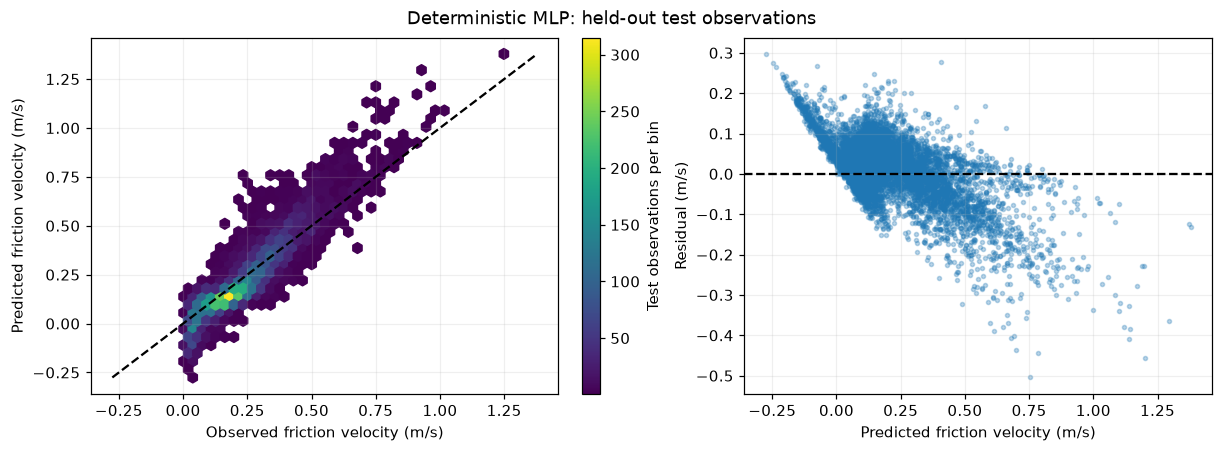

In [4]:
conf["model"]["epochs"] = 1
conf["model"]["verbose"] = 1
model = RegressorDNN(**conf["model"])
model.build_neural_network(x_train.shape[-1], y_train.shape[-1])
history = model.fit(x_train, y_train, validation_data=(x_valid,y_valid))
y_pred = model.predict(x_test, scaler=y_scaler)
metrics = point_metrics(y_test_physical, y_pred)
display(metrics)
metrics.to_csv(OUTPUT_DIR/"deterministic_test_metrics.csv")
fig, axes = plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
density = axes[0].hexbin(y_test_physical[:,0],y_pred[:,0],gridsize=35,mincnt=1)
fig.colorbar(density,ax=axes[0],label="Test observations per bin")
limits=[min(y_test_physical.min(),y_pred.min()),max(y_test_physical.max(),y_pred.max())]
axes[0].plot(limits,limits,"k--")
axes[0].set(xlabel="Observed friction velocity (m/s)",ylabel="Predicted friction velocity (m/s)")
axes[1].scatter(y_pred[:,0],(y_test_physical-y_pred)[:,0],s=7,alpha=.3)
axes[1].axhline(0,color="black",ls="--")
axes[1].set(xlabel="Predicted friction velocity (m/s)",ylabel="Residual (m/s)")
fig.suptitle("Deterministic MLP: held-out test observations")
plt.show()


### Deterministic Monte Carlo dropout

The original configuration specifies 100 passes. Their variance describes variation of the predicted mean under dropout. This deterministic model has no learned observation-noise variance, so this spread is **not a full predictive interval**.

,mae,rmse,r2
friction_velocity:surface:m_s-1,0.063021,0.084683,0.701897


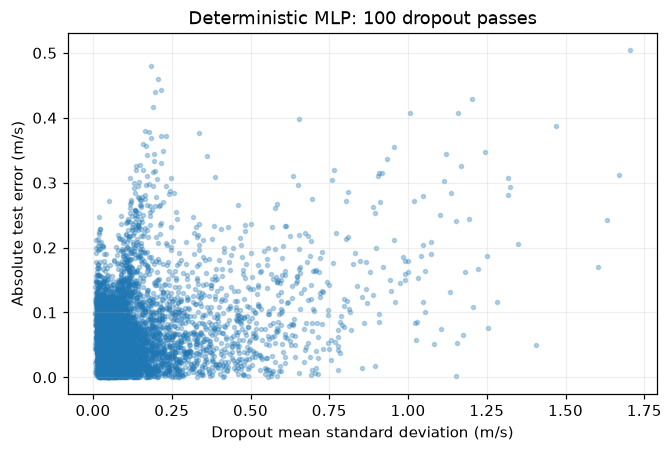

In [5]:
results = model.predict_monte_carlo(x_test, conf["ensemble"]["monte_carlo_passes"], scaler=y_scaler)
mu_ensemble = results.mean(axis=0)
var_ensemble = results.var(axis=0, ddof=0)
display(point_metrics(y_test_physical,mu_ensemble))
fig, ax = plt.subplots(figsize=(6,4),constrained_layout=True)
ax.scatter(np.sqrt(var_ensemble[:,0]),abs(y_test_physical[:,0]-mu_ensemble[:,0]),s=7,alpha=.3)
ax.set(xlabel="Dropout mean standard deviation (m/s)",ylabel="Absolute test error (m/s)",title="Deterministic MLP: 100 dropout passes")
plt.show()


## 2. Original Gaussian MLP

Model: "functional_1"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_00 (Dense)                │ (None, 342)            │         1,710 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_h_00 (Dropout)          │ (None, 342)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_01 (Dense)                │ (None, 342)            │       117,306 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_h_01 (Dropout)          │ (None, 342)            │             0 │
├─────────────────────────────────┼───────────────────

,mae,rmse,r2,nll
friction_velocity:surface:m_s-1,0.177777,0.220328,-1.017979,0.825716


,target,nominal,observed,mean_width
0,0,0.50,0.983584,1.224846
1,0,0.80,0.997078,2.327246
2,0,0.90,0.999444,2.986987
3,0,0.95,0.999722,3.559215


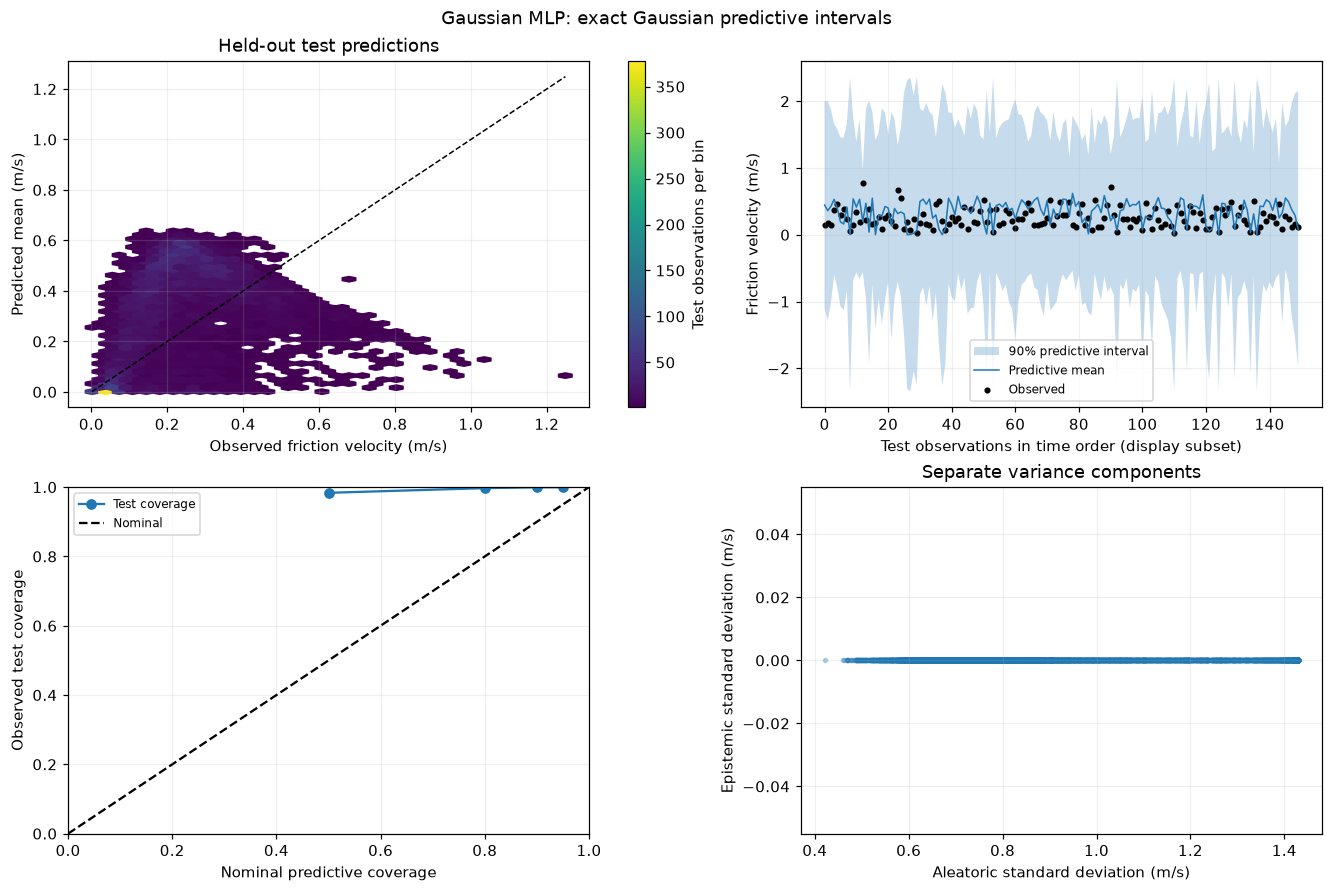

In [6]:
with (ROOT/"config/surface_layer/gaussian.yml").open() as handle:
    gaussian_conf = yaml.safe_load(handle)
gaussian_conf["model"]["epochs"] = 1
gaussian_conf["model"]["verbose"] = 1
gauss_model = GaussianRegressorDNN(**gaussian_conf["model"])
gauss_model.build_neural_network(x_train.shape[-1], y_train.shape[-1])
gauss_history = gauss_model.fit(x_train,y_train,validation_data=(x_valid,y_valid),
                                callbacks=regression_callbacks(gaussian_conf,"gaussian"))
mu, var = gauss_model.predict_uncertainty(x_test,scaler=y_scaler)
gaussian_result = evaluate_gaussian_mixture(y_test_physical,mu[None],var[None])
display(gaussian_result["metrics"])
display(gaussian_result["coverage"])
gaussian_result["metrics"].to_csv(OUTPUT_DIR/"gaussian_test_metrics.csv")
plot_regression_result(gaussian_result,"Gaussian MLP: exact Gaussian predictive intervals")


## 3. Original evidential regression model

The Normal–Inverse-Gamma output gives aleatoric variance β/(α−1) and epistemic variance β/[ν(α−1)]. Their sum is the predictive variance. NLL, PIT, and intervals use the **Student-t predictive distribution**, not a Gaussian approximation. Variances transform with the square of the inverse target-scaling factor.

Model: "functional_2"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_00 (Dense)                │ (None, 295)            │         1,475 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_h_00 (Dropout)          │ (None, 295)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DenseNormalGamma                │ (None, 4)              │         1,184 │
│ (DenseNormalGamma)              │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 2,659 (10.39 KB)
 Trainable params: 2,6

,mae,rmse,r2,nll
friction_velocity:surface:m_s-1,0.077234,0.123184,0.369204,0.214004


,target,nominal,observed,mean_width
0,0,0.50,0.701586,0.440930
1,0,0.80,0.795214,0.987711
2,0,0.90,0.836950,1.484373
3,0,0.95,0.871174,2.114087


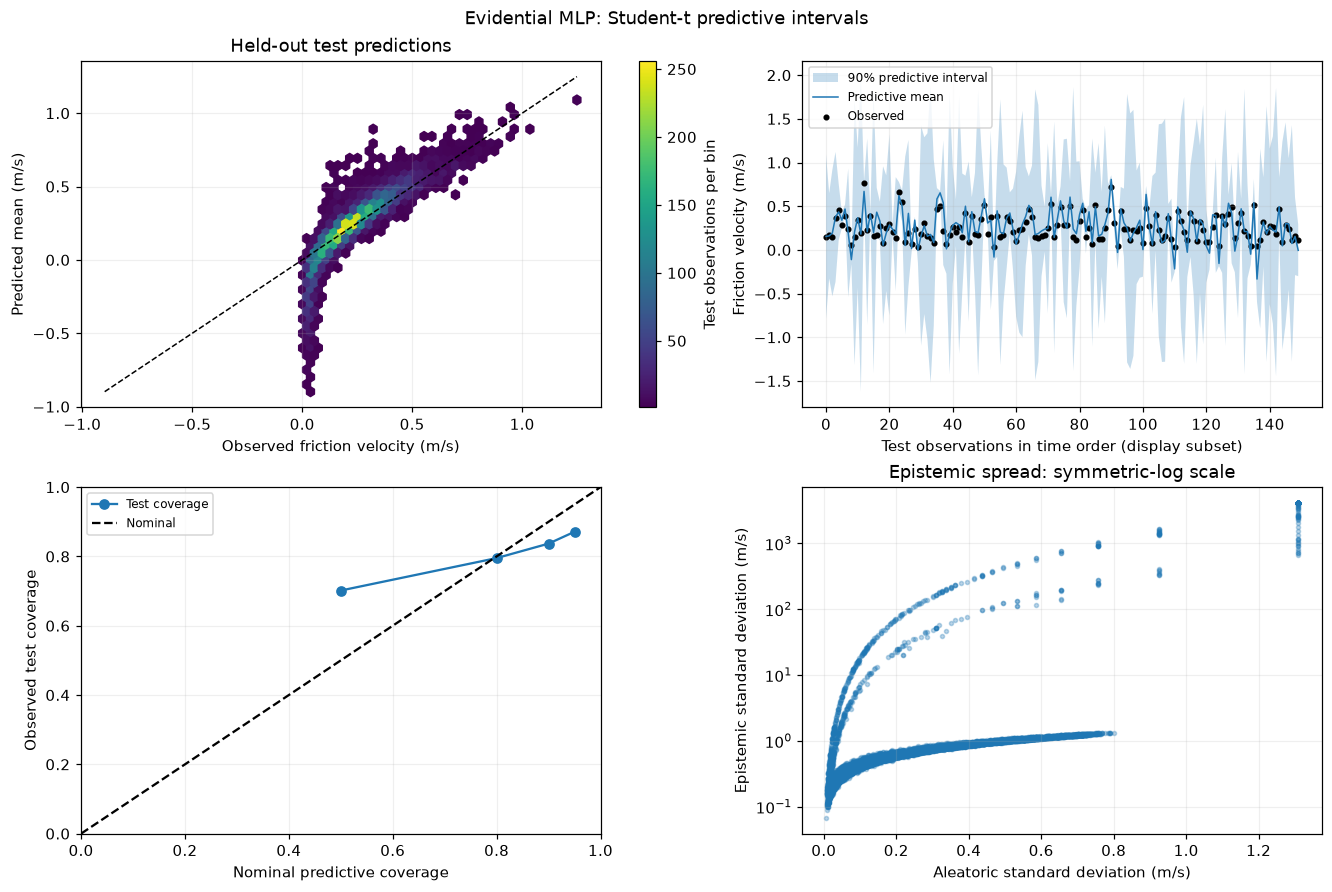

In [7]:
with (ROOT/"config/surface_layer/evidential.yml").open() as handle:
    evidential_conf = yaml.safe_load(handle)
evidential_conf["model"]["epochs"] = 5
evidential_conf["model"]["verbose"] = 1
ev_model = EvidentialRegressorDNN(**evidential_conf["model"])
ev_model.build_neural_network(x_train.shape[-1],y_train.shape[-1])
ev_history = ev_model.fit(x_train,y_train,validation_data=(x_valid,y_valid),
                          callbacks=regression_callbacks(evidential_conf,"evidential"))
parameters = ev_model.predict_dist_params(x_test)  # Parameters in scaled target units.
evidential_result = evaluate_nig(y_test_physical,parameters,y_scaler=y_scaler)
evidential_result["metrics"].index = output_cols
display(evidential_result["metrics"])
display(evidential_result["coverage"])
evidential_result["metrics"].to_csv(OUTPUT_DIR/"evidential_test_metrics.csv")
plot_regression_result(evidential_result,"Evidential MLP: Student-t predictive intervals")


## 4. Original Gaussian ensemble across two data splits

The Gaussian YAML specifies `n_models=1, n_splits=2`; the original loop trains those two members for one epoch each. Each member retains its own fitted input and target scalers. Members are combined **after** conversion to physical units:

\[V_\mathrm{aleatoric}=\operatorname{mean}_m(\sigma_m^2),\quad V_\mathrm{epistemic}=\operatorname{var}_m(\mu_m),\quad V_\mathrm{total}=V_\mathrm{aleatoric}+V_\mathrm{epistemic}.\]

Population variance (`ddof=0`) is appropriate for this equally weighted finite mixture. The evaluation below computes its exact mixture NLL and numerical mixture quantiles. No test error is used to select a member.

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


,mae,rmse,r2,nll
friction_velocity:surface:m_s-1,0.165205,0.207996,-0.798404,0.746523


,target,nominal,observed,mean_width
0,0,0.50,0.985810,1.125225
1,0,0.80,0.997496,2.141694
2,0,0.90,0.999444,2.753135
3,0,0.95,0.999722,3.286010


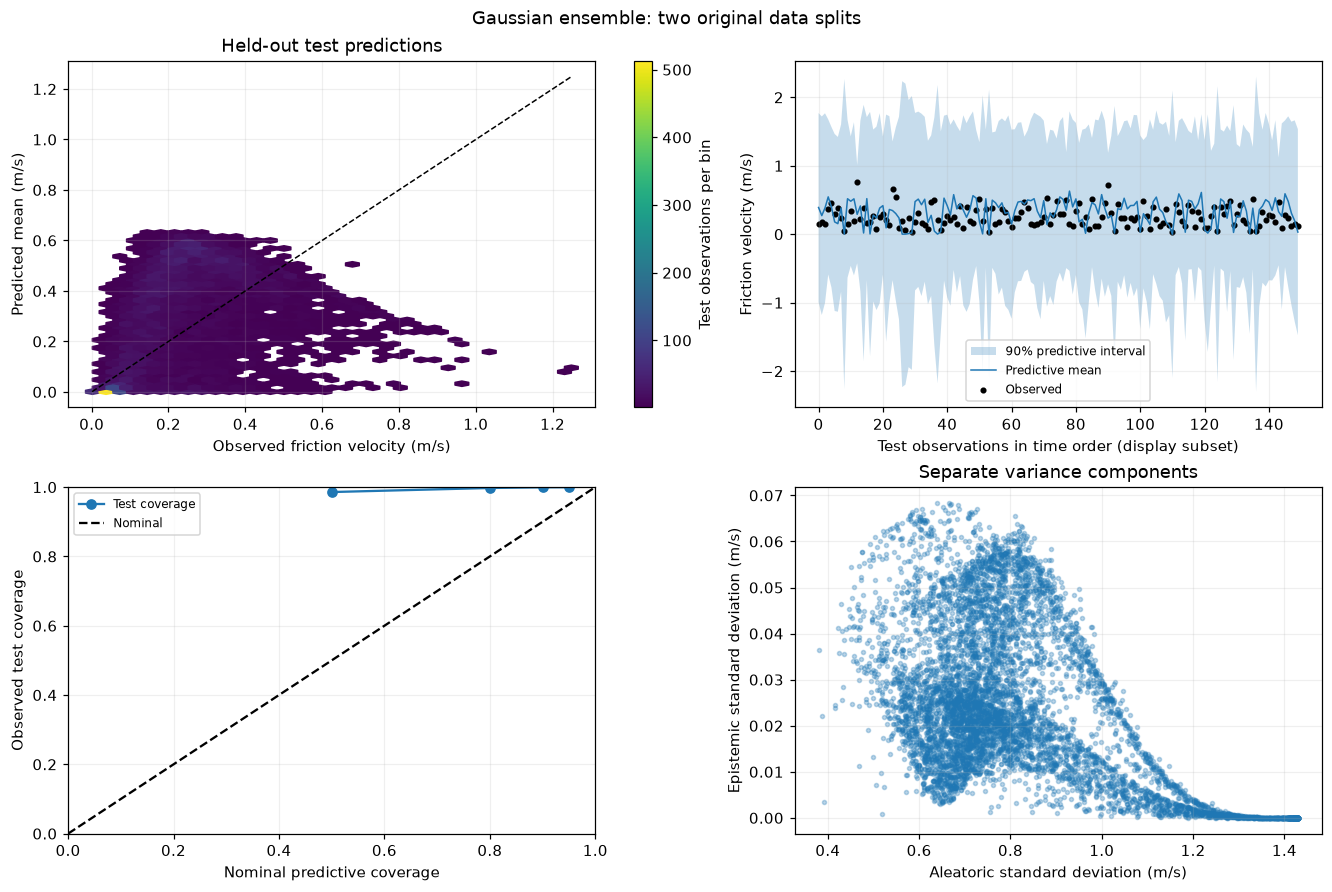

In [8]:
n_splits = gaussian_conf["ensemble"]["n_splits"]
assert gaussian_conf["ensemble"]["n_models"] == 1
member_x_scalers, member_y_scalers, member_files = [], [], []
ensemble_mu, ensemble_var = [], []
ensemble_splitter = GroupShuffleSplit(n_splits=n_splits,random_state=flat_seed,train_size=.885)
for split_id,(train_idx,valid_idx) in enumerate(ensemble_splitter.split(train_pool,groups=train_pool["day"])):
    member_train, member_valid = train_pool.iloc[train_idx],train_pool.iloc[valid_idx]
    xs,ys = RobustScaler(),MinMaxScaler((0,1))
    member_x_train = xs.fit_transform(member_train[input_cols])
    member_x_valid = xs.transform(member_valid[input_cols])
    member_y_train = ys.fit_transform(member_train[output_cols])
    member_y_valid = ys.transform(member_valid[output_cols])
    member_configuration = deepcopy(gaussian_conf)
    member_configuration["model"]["verbose"] = 0
    member = GaussianRegressorDNN(**member_configuration["model"])
    member.build_neural_network(len(input_cols),len(output_cols))
    member.fit(member_x_train,member_y_train,validation_data=(member_x_valid,member_y_valid),
               callbacks=regression_callbacks(member_configuration,f"gaussian_split{split_id}"))
    member_mu,member_var = member.predict_uncertainty(xs.transform(test_data[input_cols]),scaler=ys)
    ensemble_mu.append(member_mu)
    ensemble_var.append(member_var)
    path = OUTPUT_DIR/f"model_seed0_split{split_id}.weights.h5"
    member.model.save_weights(path)
    member_files.append(str(path))
    member_x_scalers.append(xs)
    member_y_scalers.append(ys)
ensemble_mu,ensemble_var = np.stack(ensemble_mu),np.stack(ensemble_var)
ensemble_result = evaluate_gaussian_mixture(y_test_physical,ensemble_mu,ensemble_var)
display(ensemble_result["metrics"])
display(ensemble_result["coverage"])
ensemble_result["metrics"].to_csv(OUTPUT_DIR/"ensemble_test_metrics.csv")
plot_regression_result(ensemble_result,"Gaussian ensemble: two original data splits")


### Reload the ensemble with each member's own scalers

Passing one common scaler to models trained on different transformed datasets gives incorrect predictions. Persist the scaler lists together with the model weights for later use.

In [9]:
import joblib
joblib.dump({"input_scalers":member_x_scalers,"target_scalers":member_y_scalers,
             "input_columns":input_cols,"target_columns":output_cols},OUTPUT_DIR/"ensemble_scalers.joblib")
member.ensemble_member_files = member_files
reloaded_mu,reloaded_var = member.predict_ensemble(test_data[input_cols],
        member_scalers=member_y_scalers,member_input_scalers=member_x_scalers)
np.testing.assert_allclose(reloaded_mu,ensemble_mu,rtol=1e-5,atol=1e-6)
np.testing.assert_allclose(reloaded_var,ensemble_var,rtol=1e-5,atol=1e-6)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


## 5. Gaussian Monte Carlo dropout

Keep the original ten passes, applied to the last Gaussian ensemble member as in the authors' example. This section separates mean conditional variance from between-pass mean variance; it does not combine the two-member ensemble with dropout. Every pass uses that member's own scalers.

,mae,rmse,r2,nll
friction_velocity:surface:m_s-1,0.168449,0.210788,-0.847005,0.662676


,target,nominal,observed,mean_width
0,0,0.50,0.982610,1.028375
1,0,0.80,0.997357,2.002505
2,0,0.90,0.999444,2.607552
3,0,0.95,0.999722,3.145630


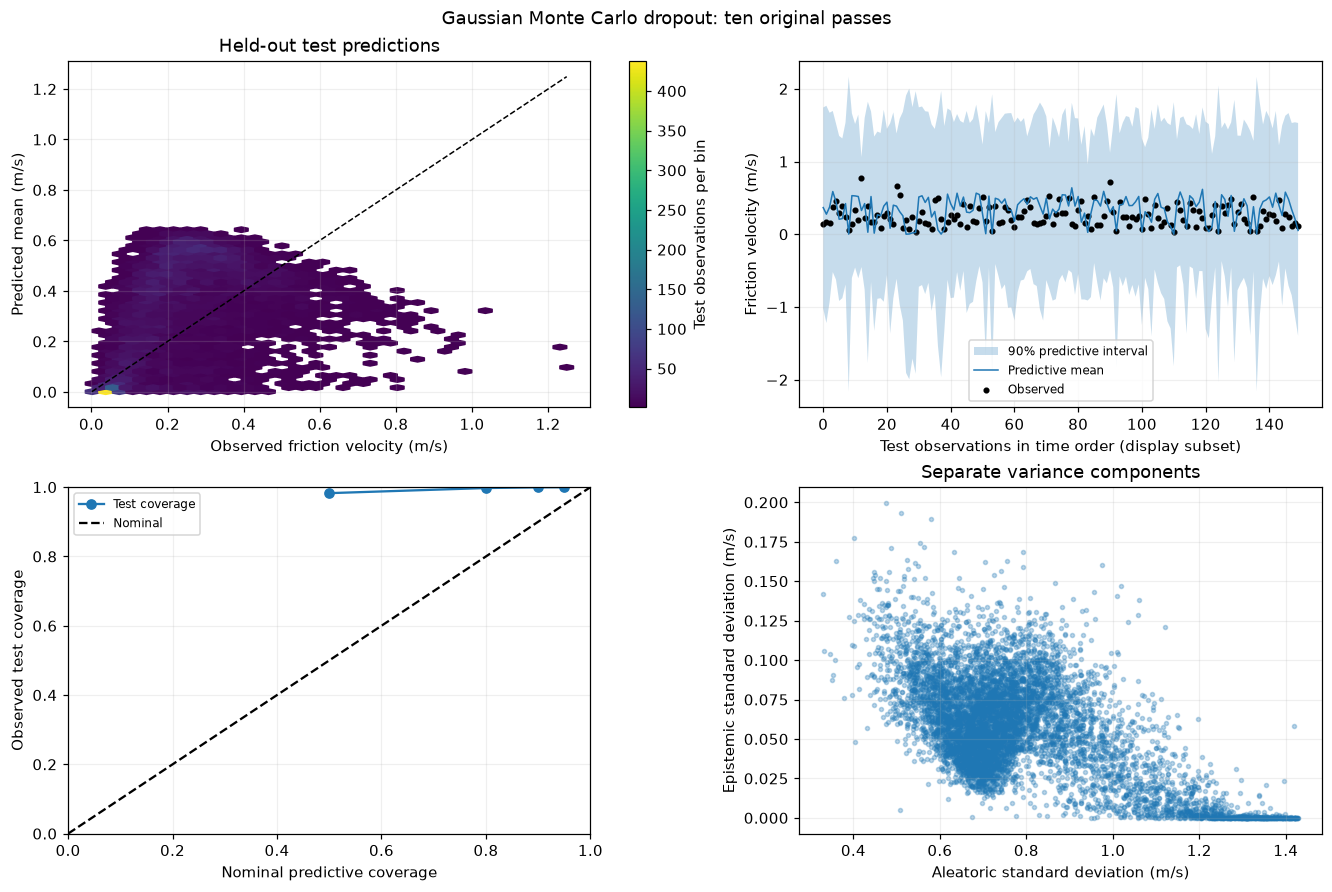

In [10]:
monte_carlo_steps = 10
mc_mu,mc_var = member.predict_monte_carlo(member_x_scalers[-1].transform(test_data[input_cols]),
    monte_carlo_steps,scaler=member_y_scalers[-1])
mc_result = evaluate_gaussian_mixture(y_test_physical,mc_mu,mc_var)
display(mc_result["metrics"])
display(mc_result["coverage"])
mc_result["metrics"].to_csv(OUTPUT_DIR/"gaussian_dropout_test_metrics.csv")
plot_regression_result(mc_result,"Gaussian Monte Carlo dropout: ten original passes")


## Interpreting these results

All reported errors and standard deviations are in friction-velocity units (m/s); variances are in (m/s)². Predictive intervals concern future target values, not confidence intervals for the fitted mean. Coverage, width, and NLL complement prediction error; low error alone does not validate uncertainty. Day-grouped test observations can still be dependent. The original one/five-epoch demonstrations may be undertrained, and this notebook deliberately retains that training budget rather than changing it to improve the displayed results.

The original short evidential fit can produce very large variances when ν is small or α approaches one. Heavy tails can give a large standard deviation even when a central predictive interval is narrower. The uncertainty panel uses a symmetric-log axis when needed to display this range without removing observations.
